# Hypergraph closing experiments

Run this notebook in the same directory as `hypergraph_epidemics.py`. It contains one executable cell for each requested task. Set `QUICK_TEST=False` for the dissertation runs.

In [1]:
from pathlib import Path
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from concurrent.futures import ProcessPoolExecutor, as_completed
from scipy.stats import t


if not Path("hypergraph_epidemics.py").exists():
    raise FileNotFoundError("Place hypergraph_epidemics.py beside this notebook.")

from hypergraph_epidemics import (
    Hypergraph, SISConfig, generate_hypergraph, power_law_weights,
    simulate_tau_leap,
)

plt.rcParams["figure.dpi"] = 120

SAVE_DIR='/scratch/kolokcse/logs_awareness_hypergraph/'

## Task 1: awareness-free SIR

Final outbreak size versus small values of beta/mu on ER, Chung-Lu, Barabasi, and Bianconi-Barabasi hypergraphs of size 10^4.

In [4]:
# TASK 1
QUICK_TEST = False
N = 10**4
SAMPLES = 3 if QUICK_TEST else 100
T_MAX = 20.0 if QUICK_TEST else 100.0
DT = 0.05 if QUICK_TEST else 0.02
RATIOS = np.linspace(0.01, 0.40, 8 if QUICK_TEST else 20)
MU = 1.0
INITIAL_INFECTED = 10
EDGE_SIZE = 5
MEAN_DEGREE = 5.0
WORKERS = max(1, (os.cpu_count() or 2) - 1)

MODELS = {
    "ER": ("er", {"m": int(round(N * MEAN_DEGREE / EDGE_SIZE)), "edge_size": EDGE_SIZE}),
    "Chung-Lu": ("chung_lu", {"mean_degree": MEAN_DEGREE, "gamma": 2.5, "edge_size": EDGE_SIZE}),
    "Barabasi": ("barabasi", {"edges_per_new_node": 1, "edge_size": EDGE_SIZE}),
    "Bianconi-Barabasi": ("bianconi_barabasi", {"edges_per_new_node": 1, "edge_size": EDGE_SIZE, "fitness_shape": 1.0}),
}

def simulate_sir(H, beta, mu, dt, t_max, initial_infected, seed):
    rng = np.random.default_rng(seed)
    state = np.zeros(H.n, dtype=np.int8)
    state[rng.choice(H.n, size=min(initial_infected, H.n), replace=False)] = 1
    for _ in range(int(np.ceil(t_max / dt))):
        infected = (state == 1).astype(float)
        if infected.sum() == 0:
            break
        edge_load = np.asarray(H.incidence.T @ infected).ravel()
        edge_load /= np.maximum(H.edge_sizes - 1.0, 1.0)
        pressure = beta * np.asarray(H.incidence @ edge_load).ravel()
        old_infected = state == 1
        new_infections = (state == 0) & (rng.random(H.n) < -np.expm1(-dt * pressure))
        new_recoveries = old_infected & (rng.random(H.n) < -math.expm1(-dt * mu))
        state[new_infections] = 1
        state[new_recoveries] = 2
    size = np.count_nonzero(state)
    return size, size / H.n

def sir_job(job):
    H = generate_hypergraph(job["generator"], job["n"], seed=job["graph_seed"], **job["params"])
    size, density = simulate_sir(H, job["ratio"] * MU, MU, DT, T_MAX, INITIAL_INFECTED, job["process_seed"])
    return {"model": job["label"], "beta_over_mu": job["ratio"], "sample": job["sample"],
            "final_size": size, "final_density": density}


In [ ]:

ss = np.random.SeedSequence(20261010)
children = ss.spawn(len(MODELS) * len(RATIOS) * SAMPLES)
jobs, q = [], 0
for label, (generator, params) in MODELS.items():
    for ratio in RATIOS:
        for sample in range(SAMPLES):
            seeds = children[q].generate_state(2)
            jobs.append({"label": label, "generator": generator, "params": params, "n": N,
                         "ratio": float(ratio), "sample": sample,
                         "graph_seed": int(seeds[0]), "process_seed": int(seeds[1])})
            q += 1

rows = []
with ProcessPoolExecutor(max_workers=WORKERS) as pool:
    futures = [pool.submit(sir_job, job) for job in jobs]
    for future in as_completed(futures):
        rows.append(future.result())

sir_raw = pd.DataFrame(rows)
sir_stats = sir_raw.groupby(["model", "beta_over_mu"], as_index=False).agg(
    mean_size=("final_size", "mean"), sem_size=("final_size", "sem"),
    mean_density=("final_density", "mean"), sem_density=("final_density", "sem"))
sir_raw.to_csv(SAVE_DIR+"sir_all_hypergraphs_raw.csv", index=False)
sir_stats.to_csv(SAVE_DIR+"sir_all_hypergraphs_summary.csv", index=False)





In [2]:
sir_stats = pd.read_csv(SAVE_DIR+"sir_all_hypergraphs_summary.csv")

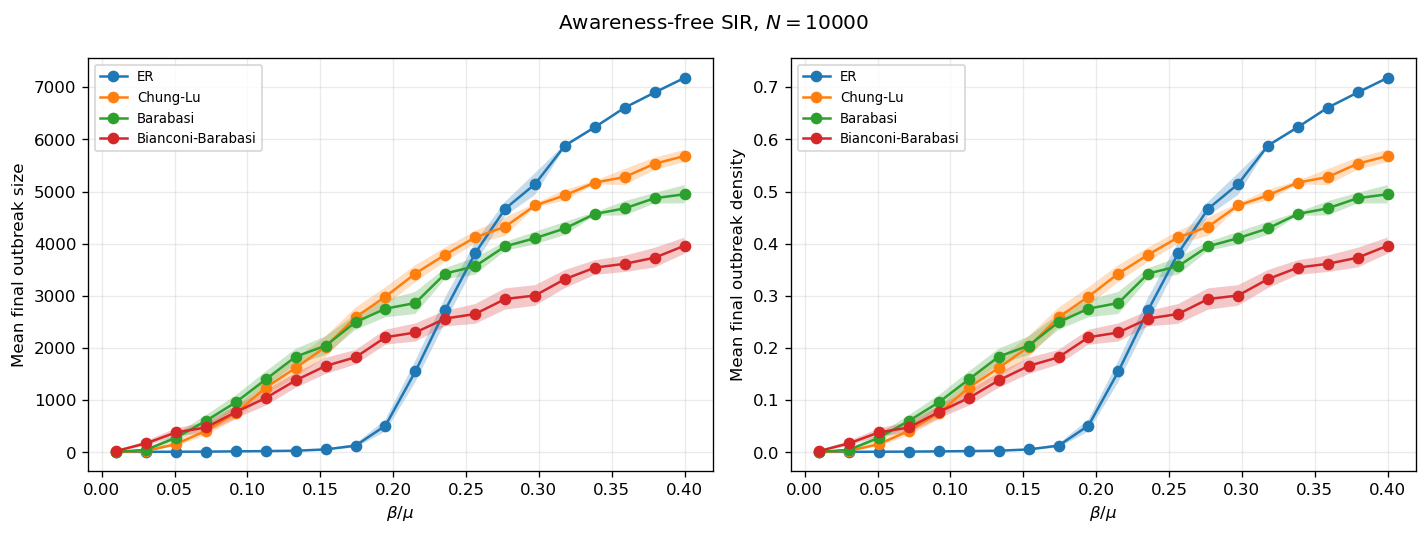

,model,beta_over_mu,mean_size,sem_size,mean_density,sem_density
0,Barabasi,0.010000,11.26,0.579031,0.001126,0.000058
1,Barabasi,0.030526,50.68,11.106117,0.005068,0.001111
2,Barabasi,0.051053,283.40,34.496748,0.028340,0.003450
3,Barabasi,0.071579,606.33,54.654016,0.060633,0.005465
4,Barabasi,0.092105,962.15,67.884799,0.096215,0.006788
...,...,...,...,...,...,...
75,ER,0.317895,5880.82,15.067098,0.588082,0.001507
76,ER,0.338421,6234.33,12.096748,0.623433,0.001210
77,ER,0.358947,6608.20,10.525160,0.660820,0.001053
78,ER,0.379474,6898.65,9.955673,0.689865,0.000996


In [5]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for label in MODELS:
    d = sir_stats[sir_stats["model"] == label]
    tcrit = t.ppf(0.975, df=SAMPLES - 1)
    ci_size = tcrit * d["sem_size"]
    ci_density = tcrit * d["sem_density"]
    # outbreak size
    axes[0].plot(
        d["beta_over_mu"],
        d["mean_size"],
        marker="o",
        label=label,
    )
    axes[0].fill_between(
        d["beta_over_mu"],
        d["mean_size"] - ci_size,
        d["mean_size"] + ci_size,
        alpha=0.25,)

    # outbreak density
    axes[1].plot(
        d["beta_over_mu"],
        d["mean_density"],
        marker="o",
        label=label,
    )
    axes[1].fill_between(
        d["beta_over_mu"],
        d["mean_density"] - ci_density,
        d["mean_density"] + ci_density,
        alpha=0.25,
    )
axes[0].set_ylabel("Mean final outbreak size")
axes[1].set_ylabel("Mean final outbreak density")
for ax in axes:
    ax.set_xlabel(r"$\beta/\mu$")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle(rf"Awareness-free SIR, $N={N}$")
fig.tight_layout()
fig.savefig("sir_all_hypergraphs.pdf", bbox_inches="tight")
plt.show()
sir_stats

In [ ]:
# TASK 1B: SIR and SIS comparison on the same hypergraph ensembles

# ============================================================
# SIS simulation
# ============================================================

def simulate_sis(
    H,
    beta,
    mu,
    dt,
    t_max,
    initial_infected,
    burn_in_fraction,
    quasi_stationary,
    seed,
):
    """
    Awareness-free SIS tau-leap simulation.

    Returns the mean number and density of infected vertices measured
    after the burn-in period.
    """

    rng = np.random.default_rng(seed)

    # False = susceptible, True = infected
    infected = np.zeros(H.n, dtype=bool)

    initially_infected = rng.choice(
        H.n,
        size=min(initial_infected, H.n),
        replace=False,
    )

    infected[initially_infected] = True

    number_of_steps = int(np.ceil(t_max / dt))
    burn_in_step = int(burn_in_fraction * number_of_steps)

    recovery_probability = -np.expm1(-dt * mu)

    infected_sum = 0.0
    number_of_observations = 0

    for step in range(number_of_steps):

        infected_float = infected.astype(float)

        # Number of infected vertices in each hyperedge
        edge_load = np.asarray(
            H.incidence.T @ infected_float
        ).ravel()

        # Normalized linear infection pressure
        edge_load /= np.maximum(
            H.edge_sizes - 1.0,
            1.0,
        )

        pressure = beta * np.asarray(
            H.incidence @ edge_load
        ).ravel()

        infection_probability = -np.expm1(
            -dt * pressure
        )

        # Transitions are based on the state at the beginning
        # of the time step.
        old_infected = infected.copy()

        new_infections = (
            (~old_infected)
            & (
                rng.random(H.n)
                < infection_probability
            )
        )

        new_recoveries = (
            old_infected
            & (
                rng.random(H.n)
                < recovery_probability
            )
        )

        infected[new_infections] = True
        infected[new_recoveries] = False

        # Quasi-stationary replacement after extinction
        if quasi_stationary and not infected.any():
            infected[rng.integers(H.n)] = True

        if step >= burn_in_step:
            infected_sum += infected.sum()
            number_of_observations += 1

    mean_infected = (
        infected_sum
        / max(number_of_observations, 1)
    )

    mean_density = mean_infected / H.n

    return mean_infected, mean_density


# ============================================================
# One parallel SIS job
# ============================================================

def sis_job(job):

    H = generate_hypergraph(
        job["generator"],
        job["n"],
        seed=job["graph_seed"],
        **job["params"],
    )

    mean_size, mean_density = simulate_sis(
        H=H,
        beta=job["ratio"] * MU,
        mu=MU,
        dt=DT,
        t_max=T_MAX,
        initial_infected=INITIAL_INFECTED,
        burn_in_fraction=0.5,
        quasi_stationary=True,
        seed=job["process_seed"],
    )

    return {
        "model": job["label"],
        "beta_over_mu": job["ratio"],
        "sample": job["sample"],
        "mean_size": mean_size,
        "mean_density": mean_density,
    }


# ============================================================
# Construct parallel SIS jobs
# ============================================================

sis_seed_sequence = np.random.SeedSequence(
    20261011
)

sis_children = sis_seed_sequence.spawn(
    len(MODELS)
    * len(RATIOS)
    * SAMPLES
)

sis_jobs = []
q = 0

for label, (generator, params) in MODELS.items():

    for ratio in RATIOS:

        for sample in range(SAMPLES):

            seeds = sis_children[q].generate_state(2)

            sis_jobs.append(
                {
                    "label": label,
                    "generator": generator,
                    "params": params,
                    "n": N,
                    "ratio": float(ratio),
                    "sample": sample,
                    "graph_seed": int(seeds[0]),
                    "process_seed": int(seeds[1]),
                }
            )

            q += 1


# ============================================================
# Run parallel SIS simulations
# ============================================================

sis_rows = []

with ProcessPoolExecutor(
    max_workers=WORKERS
) as pool:

    futures = [
        pool.submit(
            sis_job,
            job,
        )
        for job in sis_jobs
    ]

    for future in as_completed(futures):
        sis_rows.append(
            future.result()
        )


# ============================================================
# Aggregate SIS results
# ============================================================

sis_raw = pd.DataFrame(
    sis_rows
)

sis_stats = (
    sis_raw
    .groupby(
        [
            "model",
            "beta_over_mu",
        ],
        as_index=False,
    )
    .agg(
        mean_size=(
            "mean_size",
            "mean",
        ),
        sem_size=(
            "mean_size",
            "sem",
        ),
        mean_density=(
            "mean_density",
            "mean",
        ),
        sem_density=(
            "mean_density",
            "sem",
        ),
        number_of_samples=(
            "mean_density",
            "size",
        ),
    )
)


# ============================================================
# Save SIS results
# ============================================================

sis_raw.to_csv(
    SAVE_DIR
    + "sis_all_hypergraphs_raw.csv",
    index=False,
)

sis_stats.to_csv(
    SAVE_DIR
    + "sis_all_hypergraphs_summary.csv",
    index=False,
)


In [6]:
sis_stats = pd.read_csv(SAVE_DIR + "sis_all_hypergraphs_summary.csv")

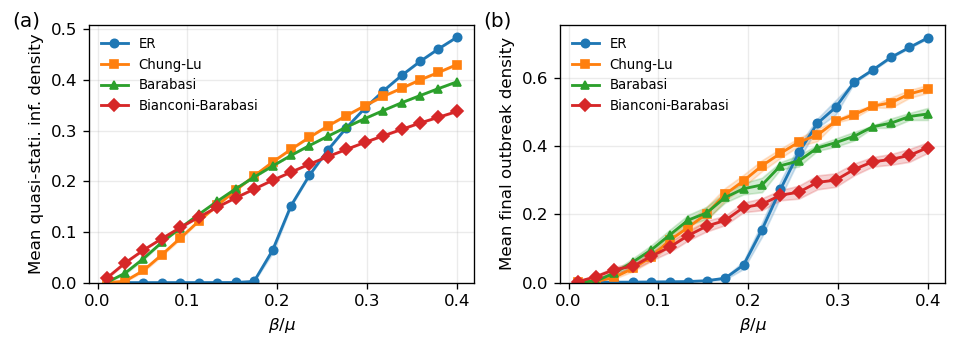

,model,beta_over_mu,mean_size,sem_size,mean_density,sem_density,number_of_samples
0,Barabasi,0.010000,1.341224,0.092677,0.000134,0.000009,100
1,Barabasi,0.030526,187.598432,8.574462,0.018760,0.000857,100
2,Barabasi,0.051053,475.658724,11.395013,0.047566,0.001140,100
3,Barabasi,0.071579,796.503364,2.336396,0.079650,0.000234,100
4,Barabasi,0.092105,1079.079320,0.881075,0.107908,0.000088,100
...,...,...,...,...,...,...,...
75,ER,0.317895,3782.906472,1.581195,0.378291,0.000158,100
76,ER,0.338421,4092.315492,1.553897,0.409232,0.000155,100
77,ER,0.358947,4368.551944,1.213626,0.436855,0.000121,100
78,ER,0.379474,4616.664500,1.340284,0.461666,0.000134,100


In [16]:


# ============================================================
# Combined SIR-SIS figure
#
# Left:  SIR final outbreak density
# Right: SIS metastable infection density
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 3),
    sharex=True,
)

colors = {
    "ER": "tab:blue",
    "Chung-Lu": "tab:orange",
    "Barabasi": "tab:green",
    "Bianconi-Barabasi": "tab:red",
}

markers = {
    "ER": "o",
    "Chung-Lu": "s",
    "Barabasi": "^",
    "Bianconi-Barabasi": "D",
}

# panel labels
axes[0].text(
    -0.2, 1.05, "(a)",
    transform=axes[0].transAxes,
    va="top",
    fontsize=12,
)

axes[1].text(
    -0.2, 1.05, "(b)",
    transform=axes[1].transAxes,
    va="top",
    fontsize=12,
)
# ------------------------------------------------------------
# Panel (a): SIR
# ------------------------------------------------------------

for label in MODELS:

    d = (
        sir_stats[
            sir_stats["model"] == label
        ]
        .sort_values("beta_over_mu")
        .copy()
    )

    number_of_samples = SAMPLES

    tcrit = t.ppf(
        0.975,
        df=number_of_samples - 1,
    )

    ci_density = (
        tcrit
        * d["sem_density"]
    )

    lower = np.maximum(
        d["mean_density"]
        - ci_density,
        0.0,
    )

    upper = np.minimum(
        d["mean_density"]
        + ci_density,
        1.0,
    )

    axes[1].plot(
        d["beta_over_mu"],
        d["mean_density"],
        marker=markers[label],
        color=colors[label],
        linewidth=1.7,
        markersize=5,
        label=label,
    )

    axes[1].fill_between(
        d["beta_over_mu"],
        lower,
        upper,
        color=colors[label],
        alpha=0.20,
    )


# ------------------------------------------------------------
# Panel (b): SIS
# ------------------------------------------------------------

for label in MODELS:

    d = (
        sis_stats[
            sis_stats["model"] == label
        ]
        .sort_values("beta_over_mu")
        .copy()
    )

    tcrit = t.ppf(
        0.975,
        df=d["number_of_samples"] - 1,
    )

    ci_density = (
        tcrit
        * d["sem_density"]
    )

    lower = np.maximum(
        d["mean_density"]
        - ci_density,
        0.0,
    )

    upper = np.minimum(
        d["mean_density"]
        + ci_density,
        1.0,
    )

    axes[0].plot(
        d["beta_over_mu"],
        d["mean_density"],
        marker=markers[label],
        color=colors[label],
        linewidth=1.7,
        markersize=5,
        label=label,
    )

    axes[0].fill_between(
        d["beta_over_mu"],
        lower,
        upper,
        color=colors[label],
        alpha=0.20,
    )


# ============================================================
# Figure formatting
# ============================================================

axes[1].set_ylabel(
    "Mean final outbreak density"
)

axes[0].set_ylabel(
    "Mean quasi-stati. inf. density"
)

for ax in axes:

    ax.set_xlabel(
        r"$\beta/\mu$"
    )

    ax.set_ylim(
        bottom=0.0
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=8,
        frameon=False,
    )

fig.tight_layout()

fig.savefig(
    "sir_sis_hypergraph_density_comparison.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "sir_sis_hypergraph_density_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

sis_stats

## Task 2: SIS awareness and hyperedge-size heterogeneity

Uses |h| = 2 + Poisson(lambda_h), varies lambda_h jointly with the Chung-Lu hyperdegree exponent gamma, and produces epidemic-density heatmaps, fractal-dimension heatmaps, and degree-conditioned prevalence plots.

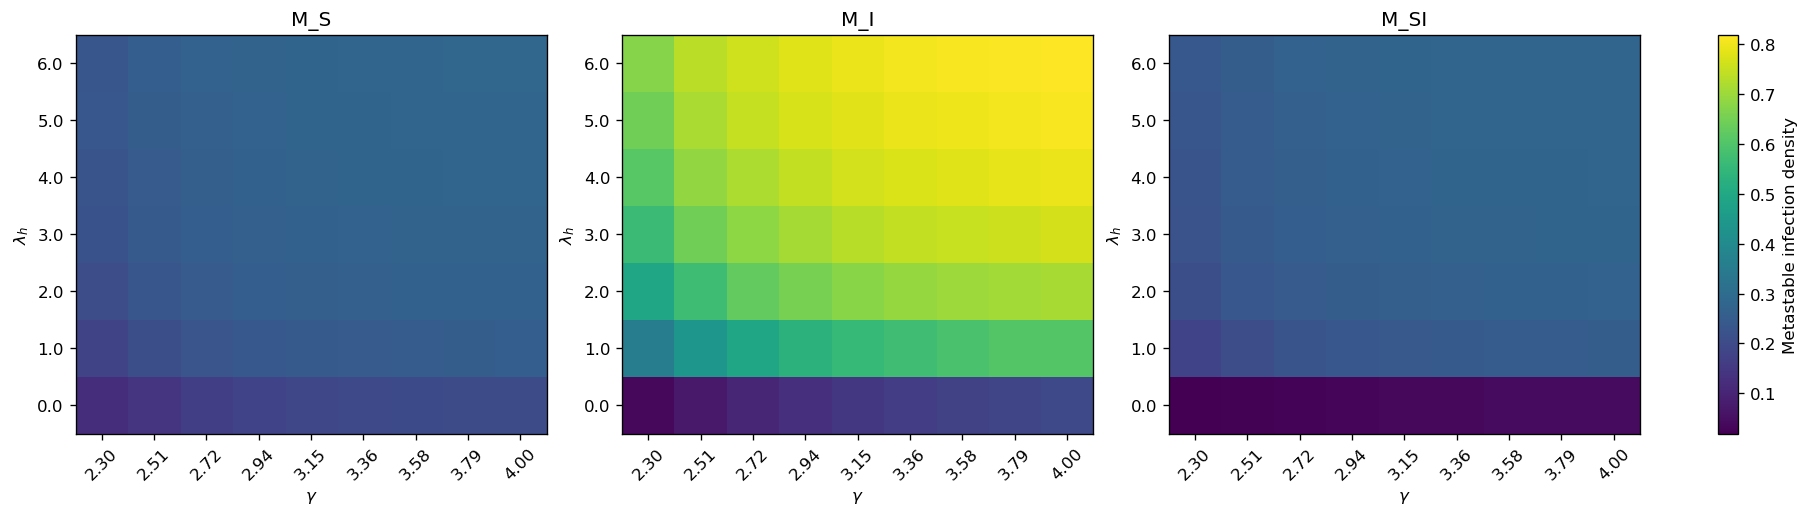

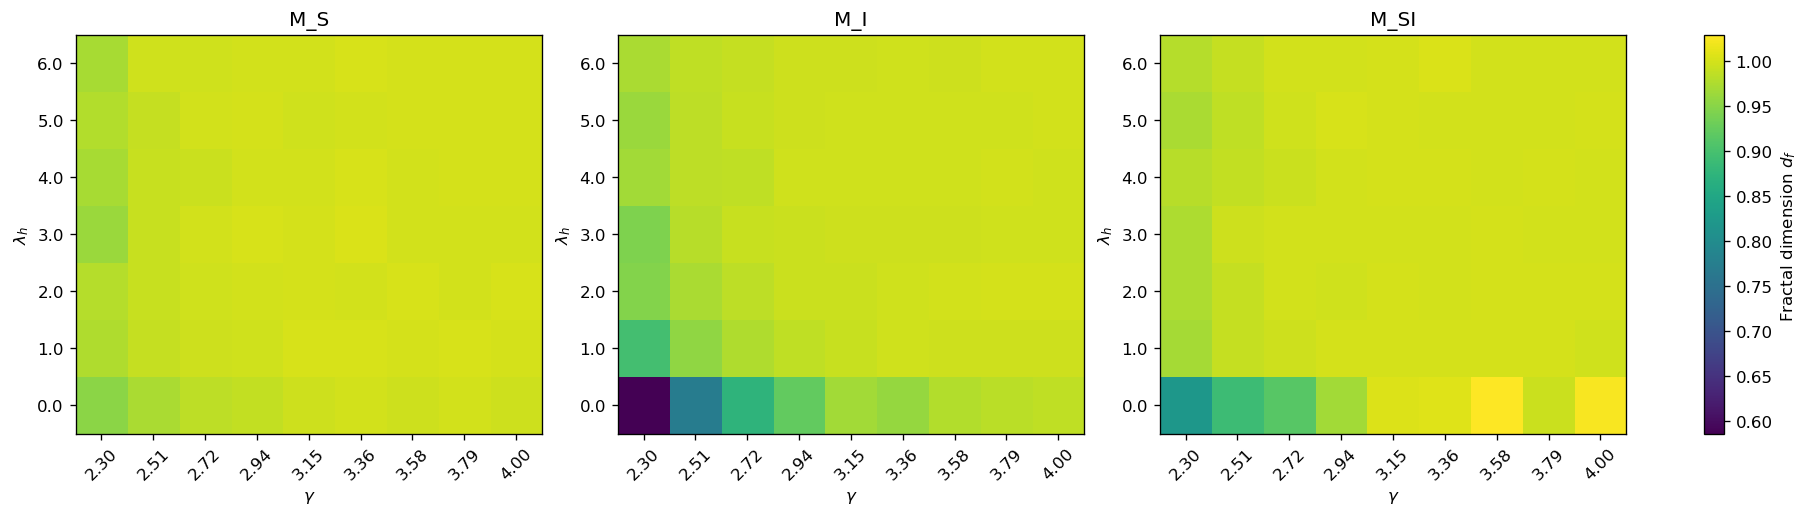

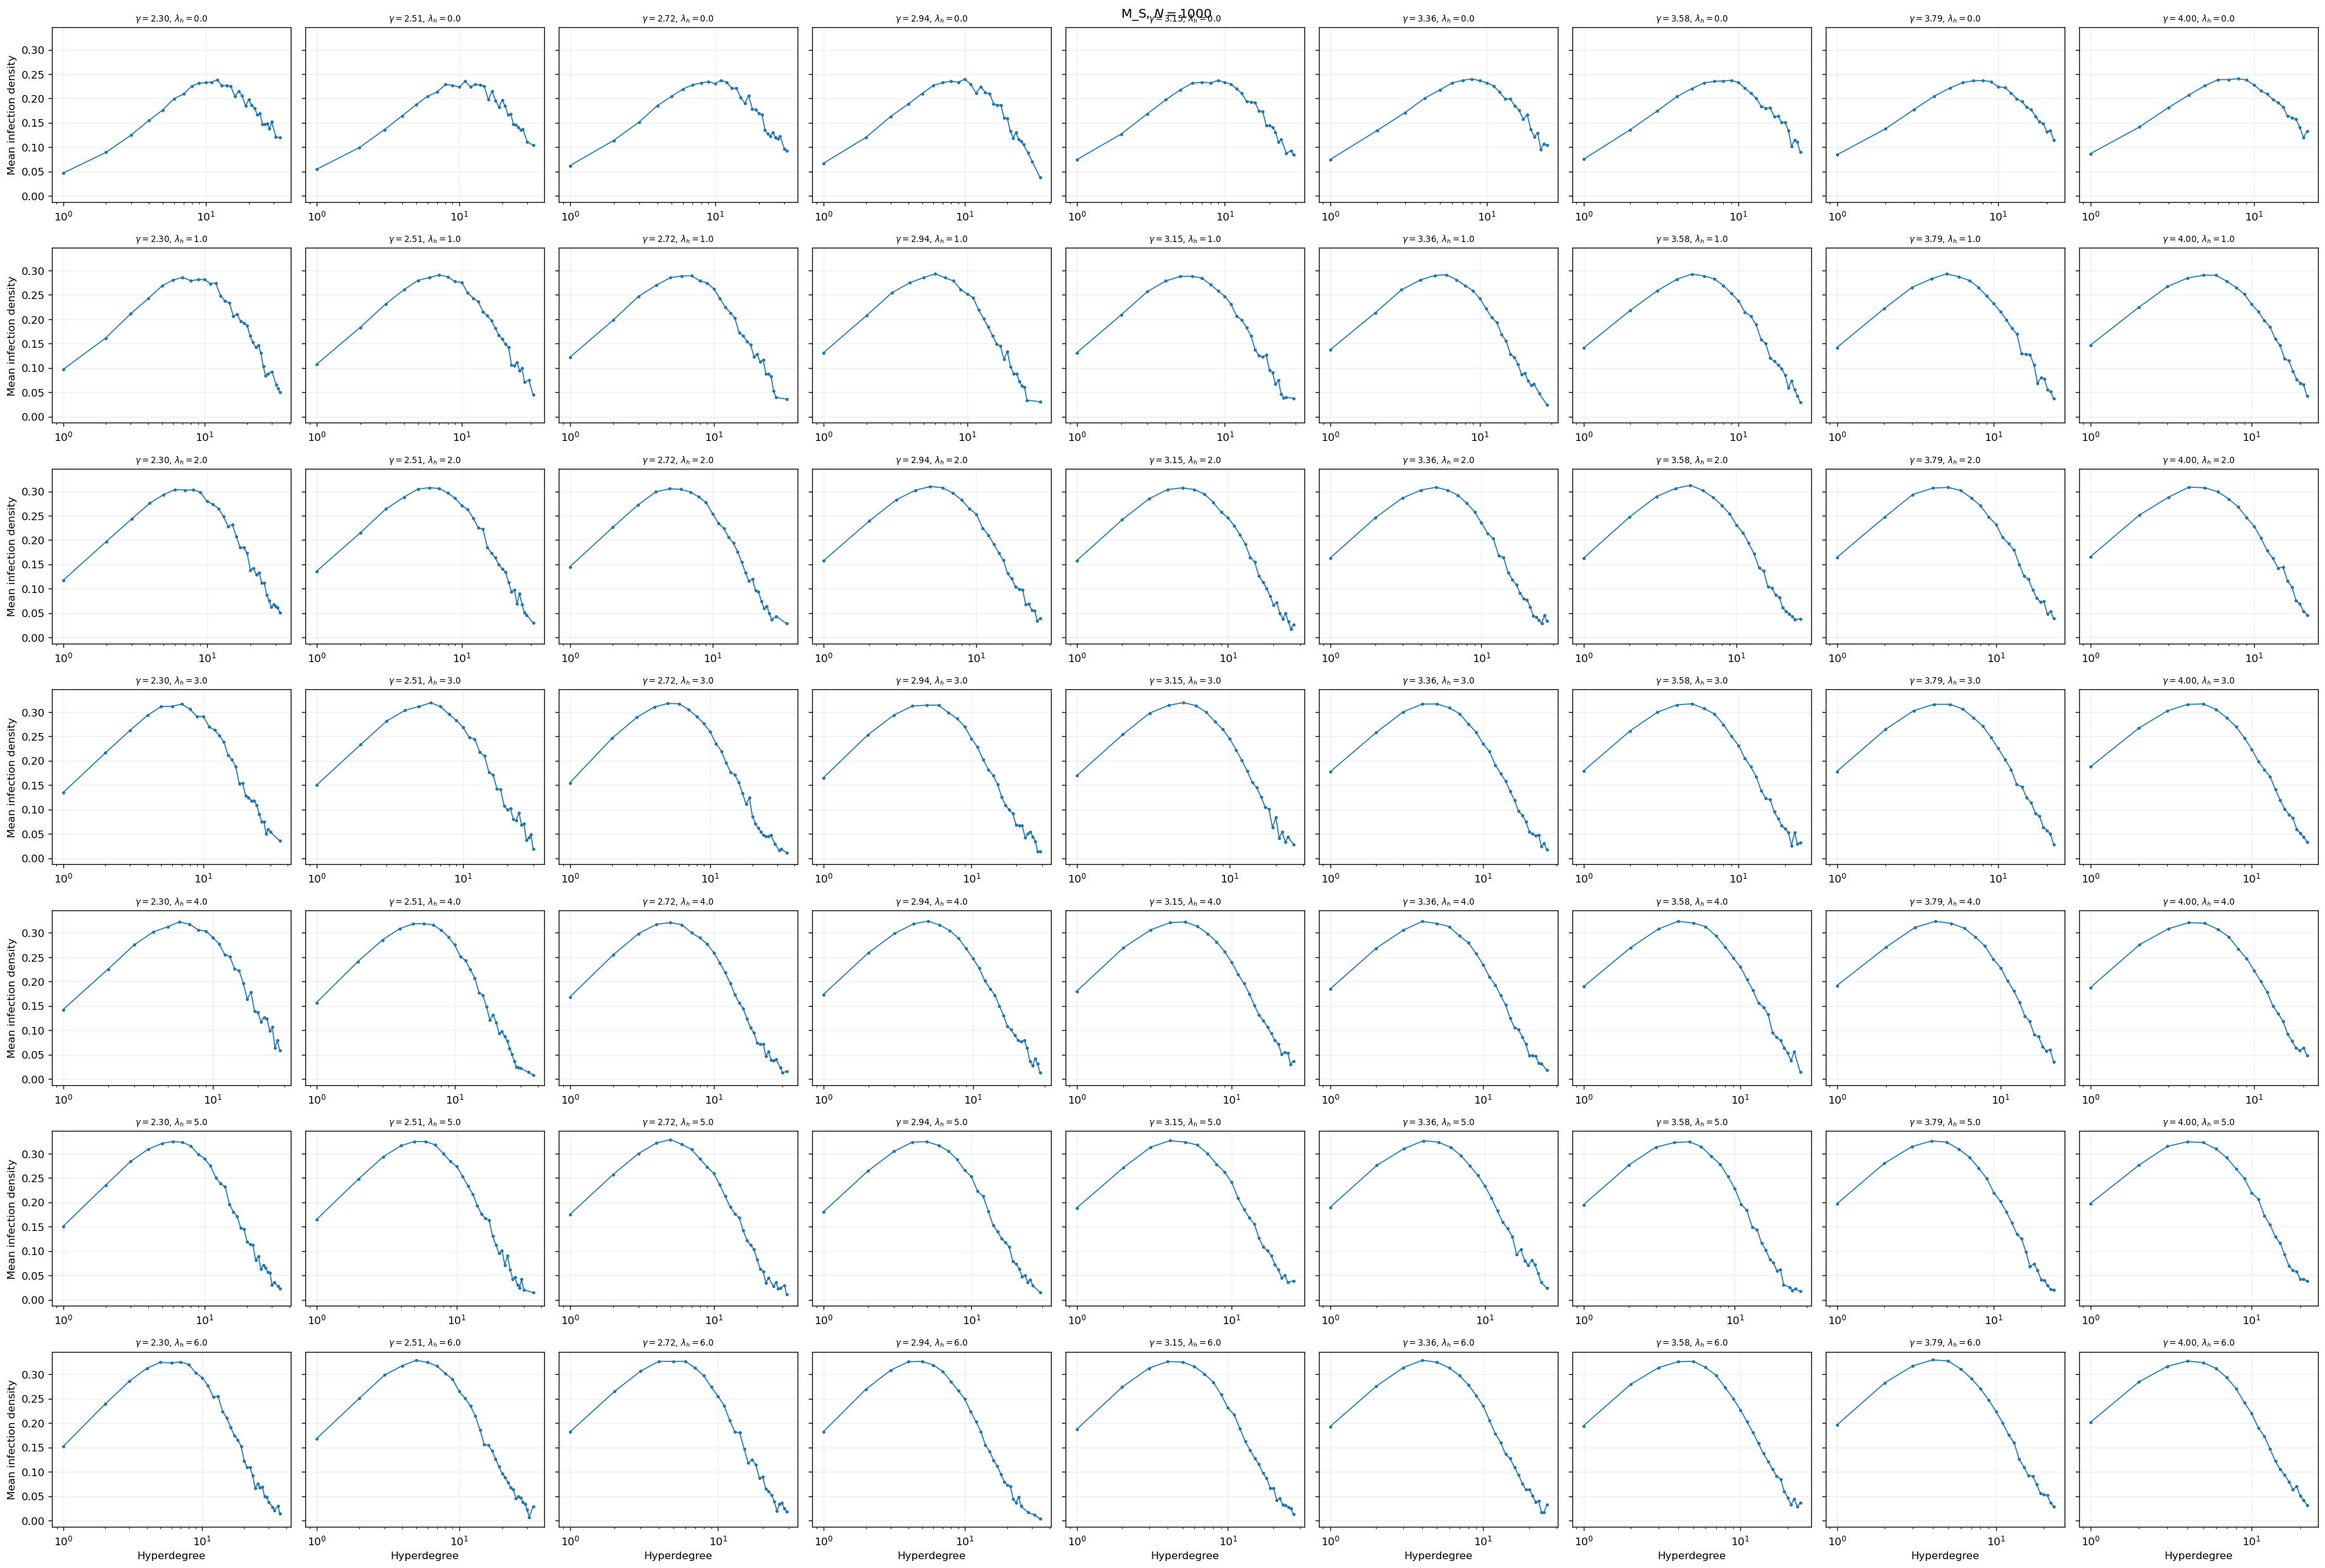

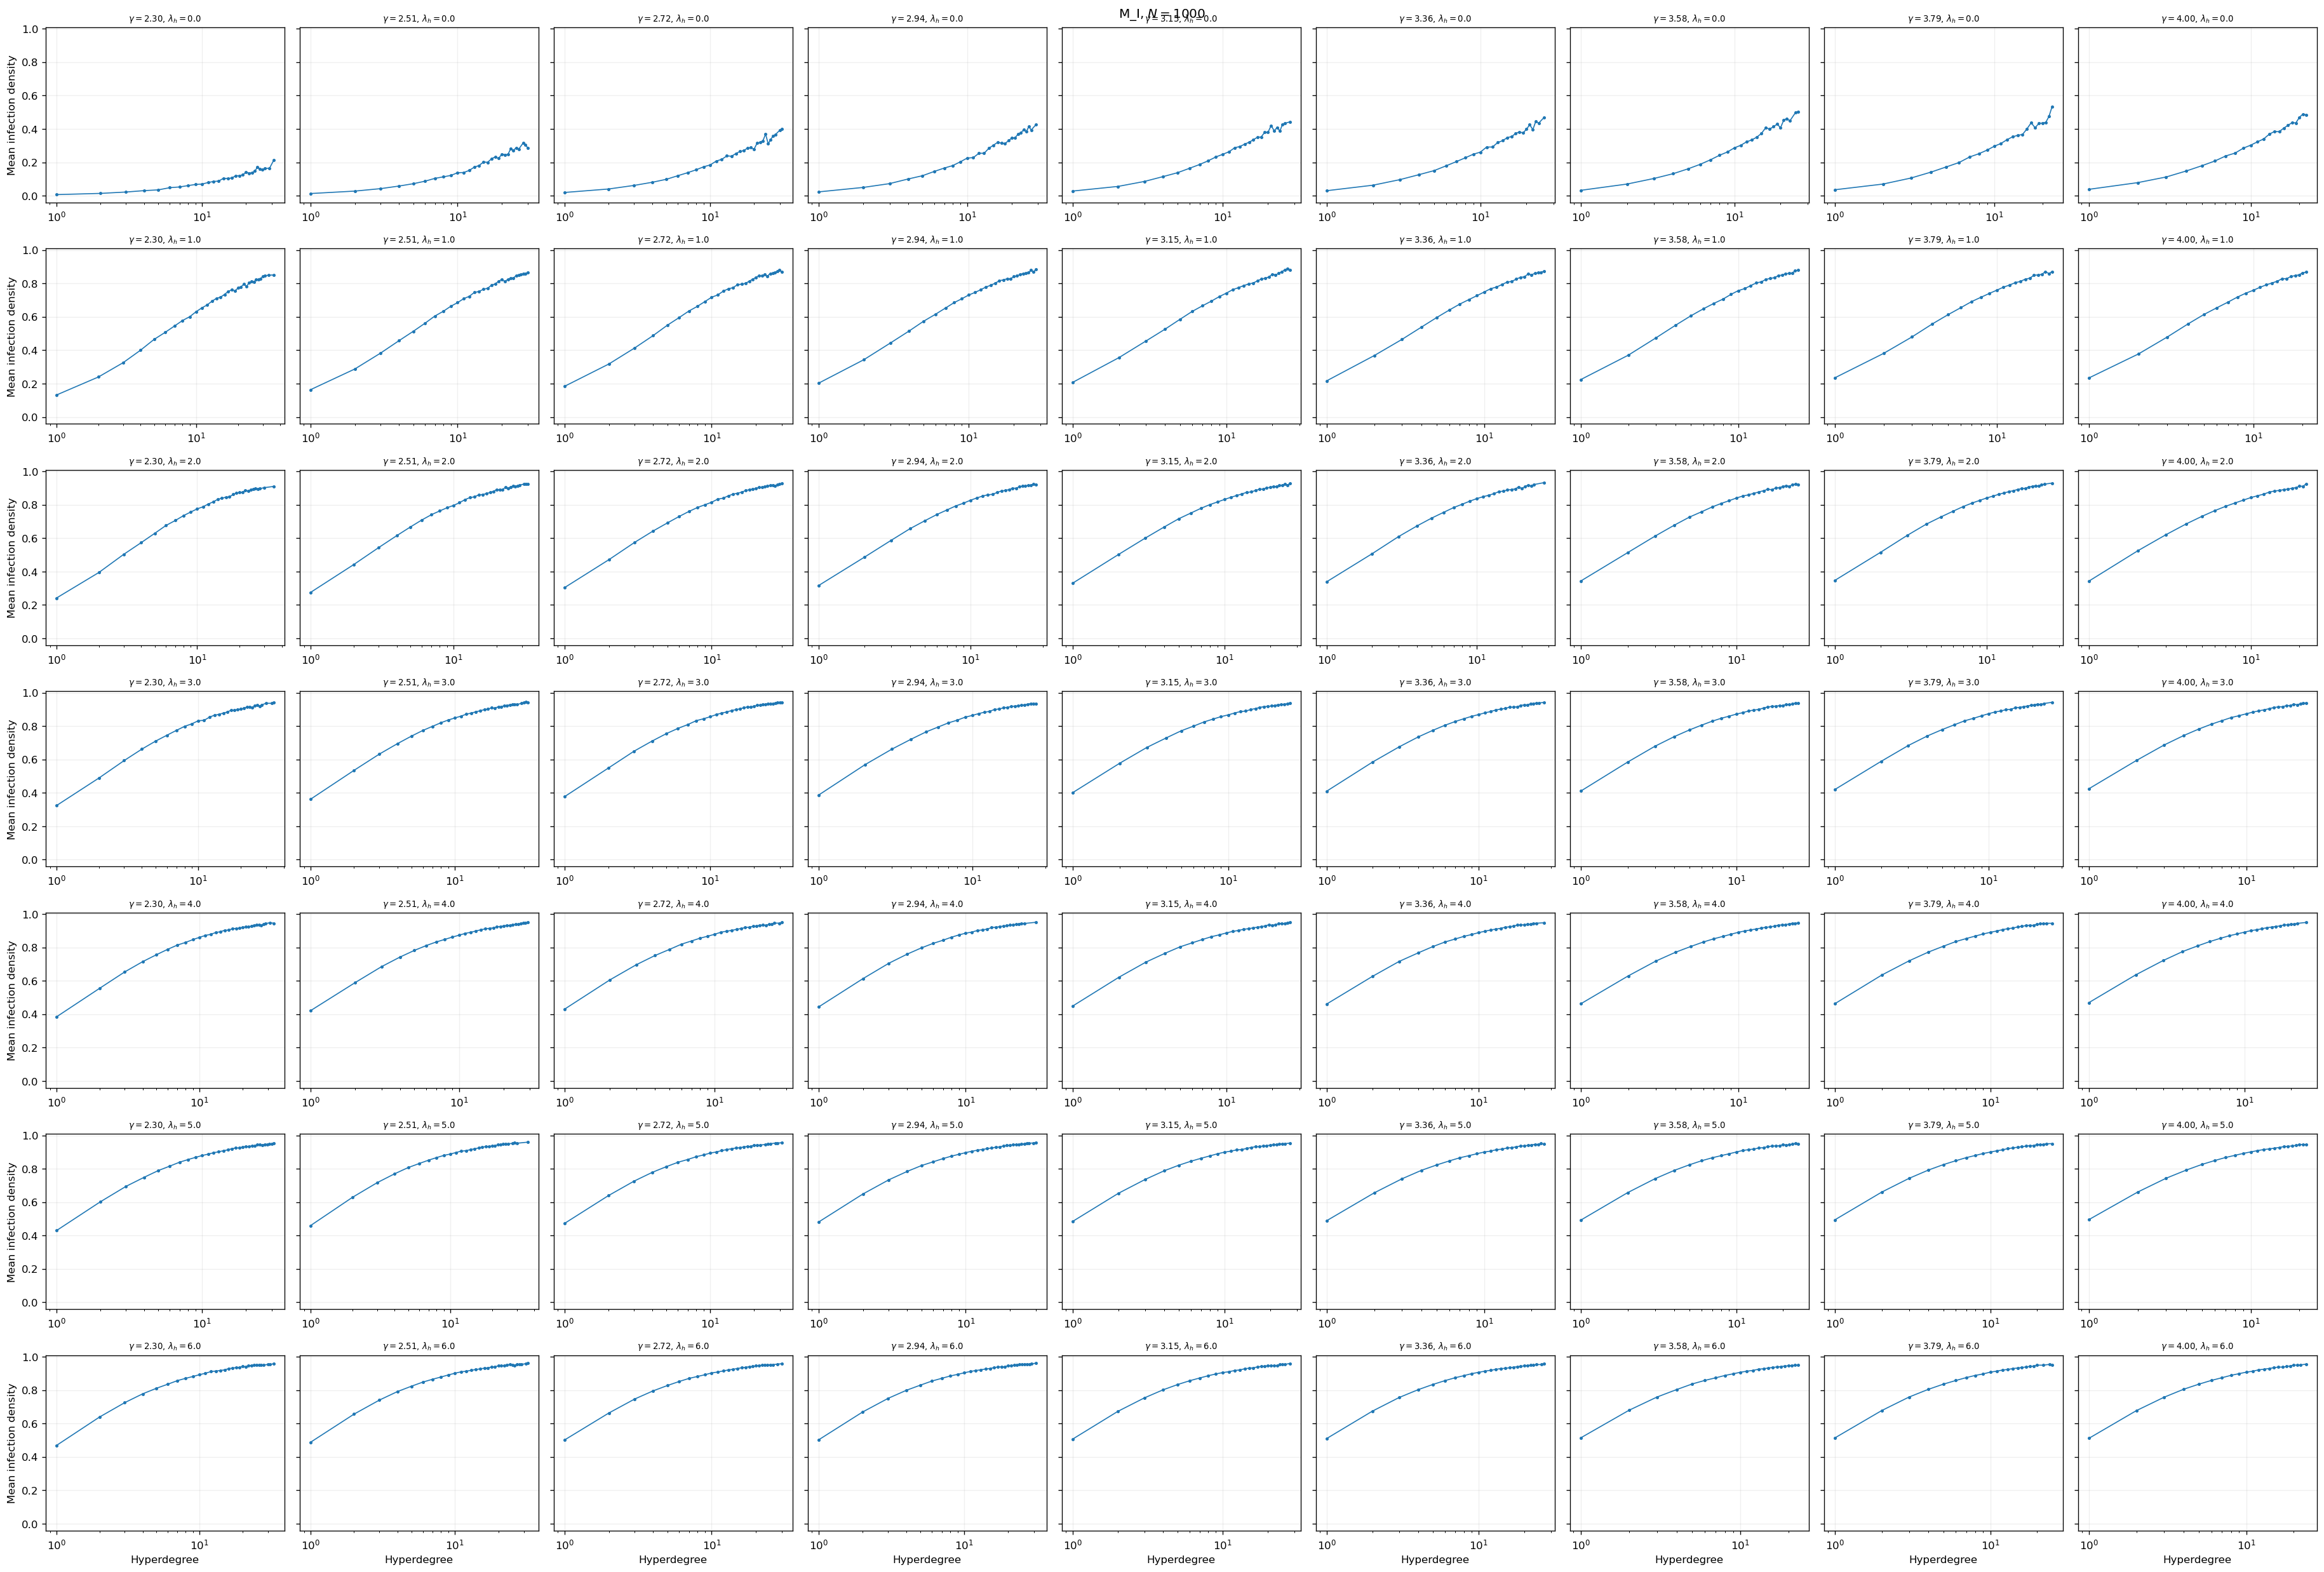

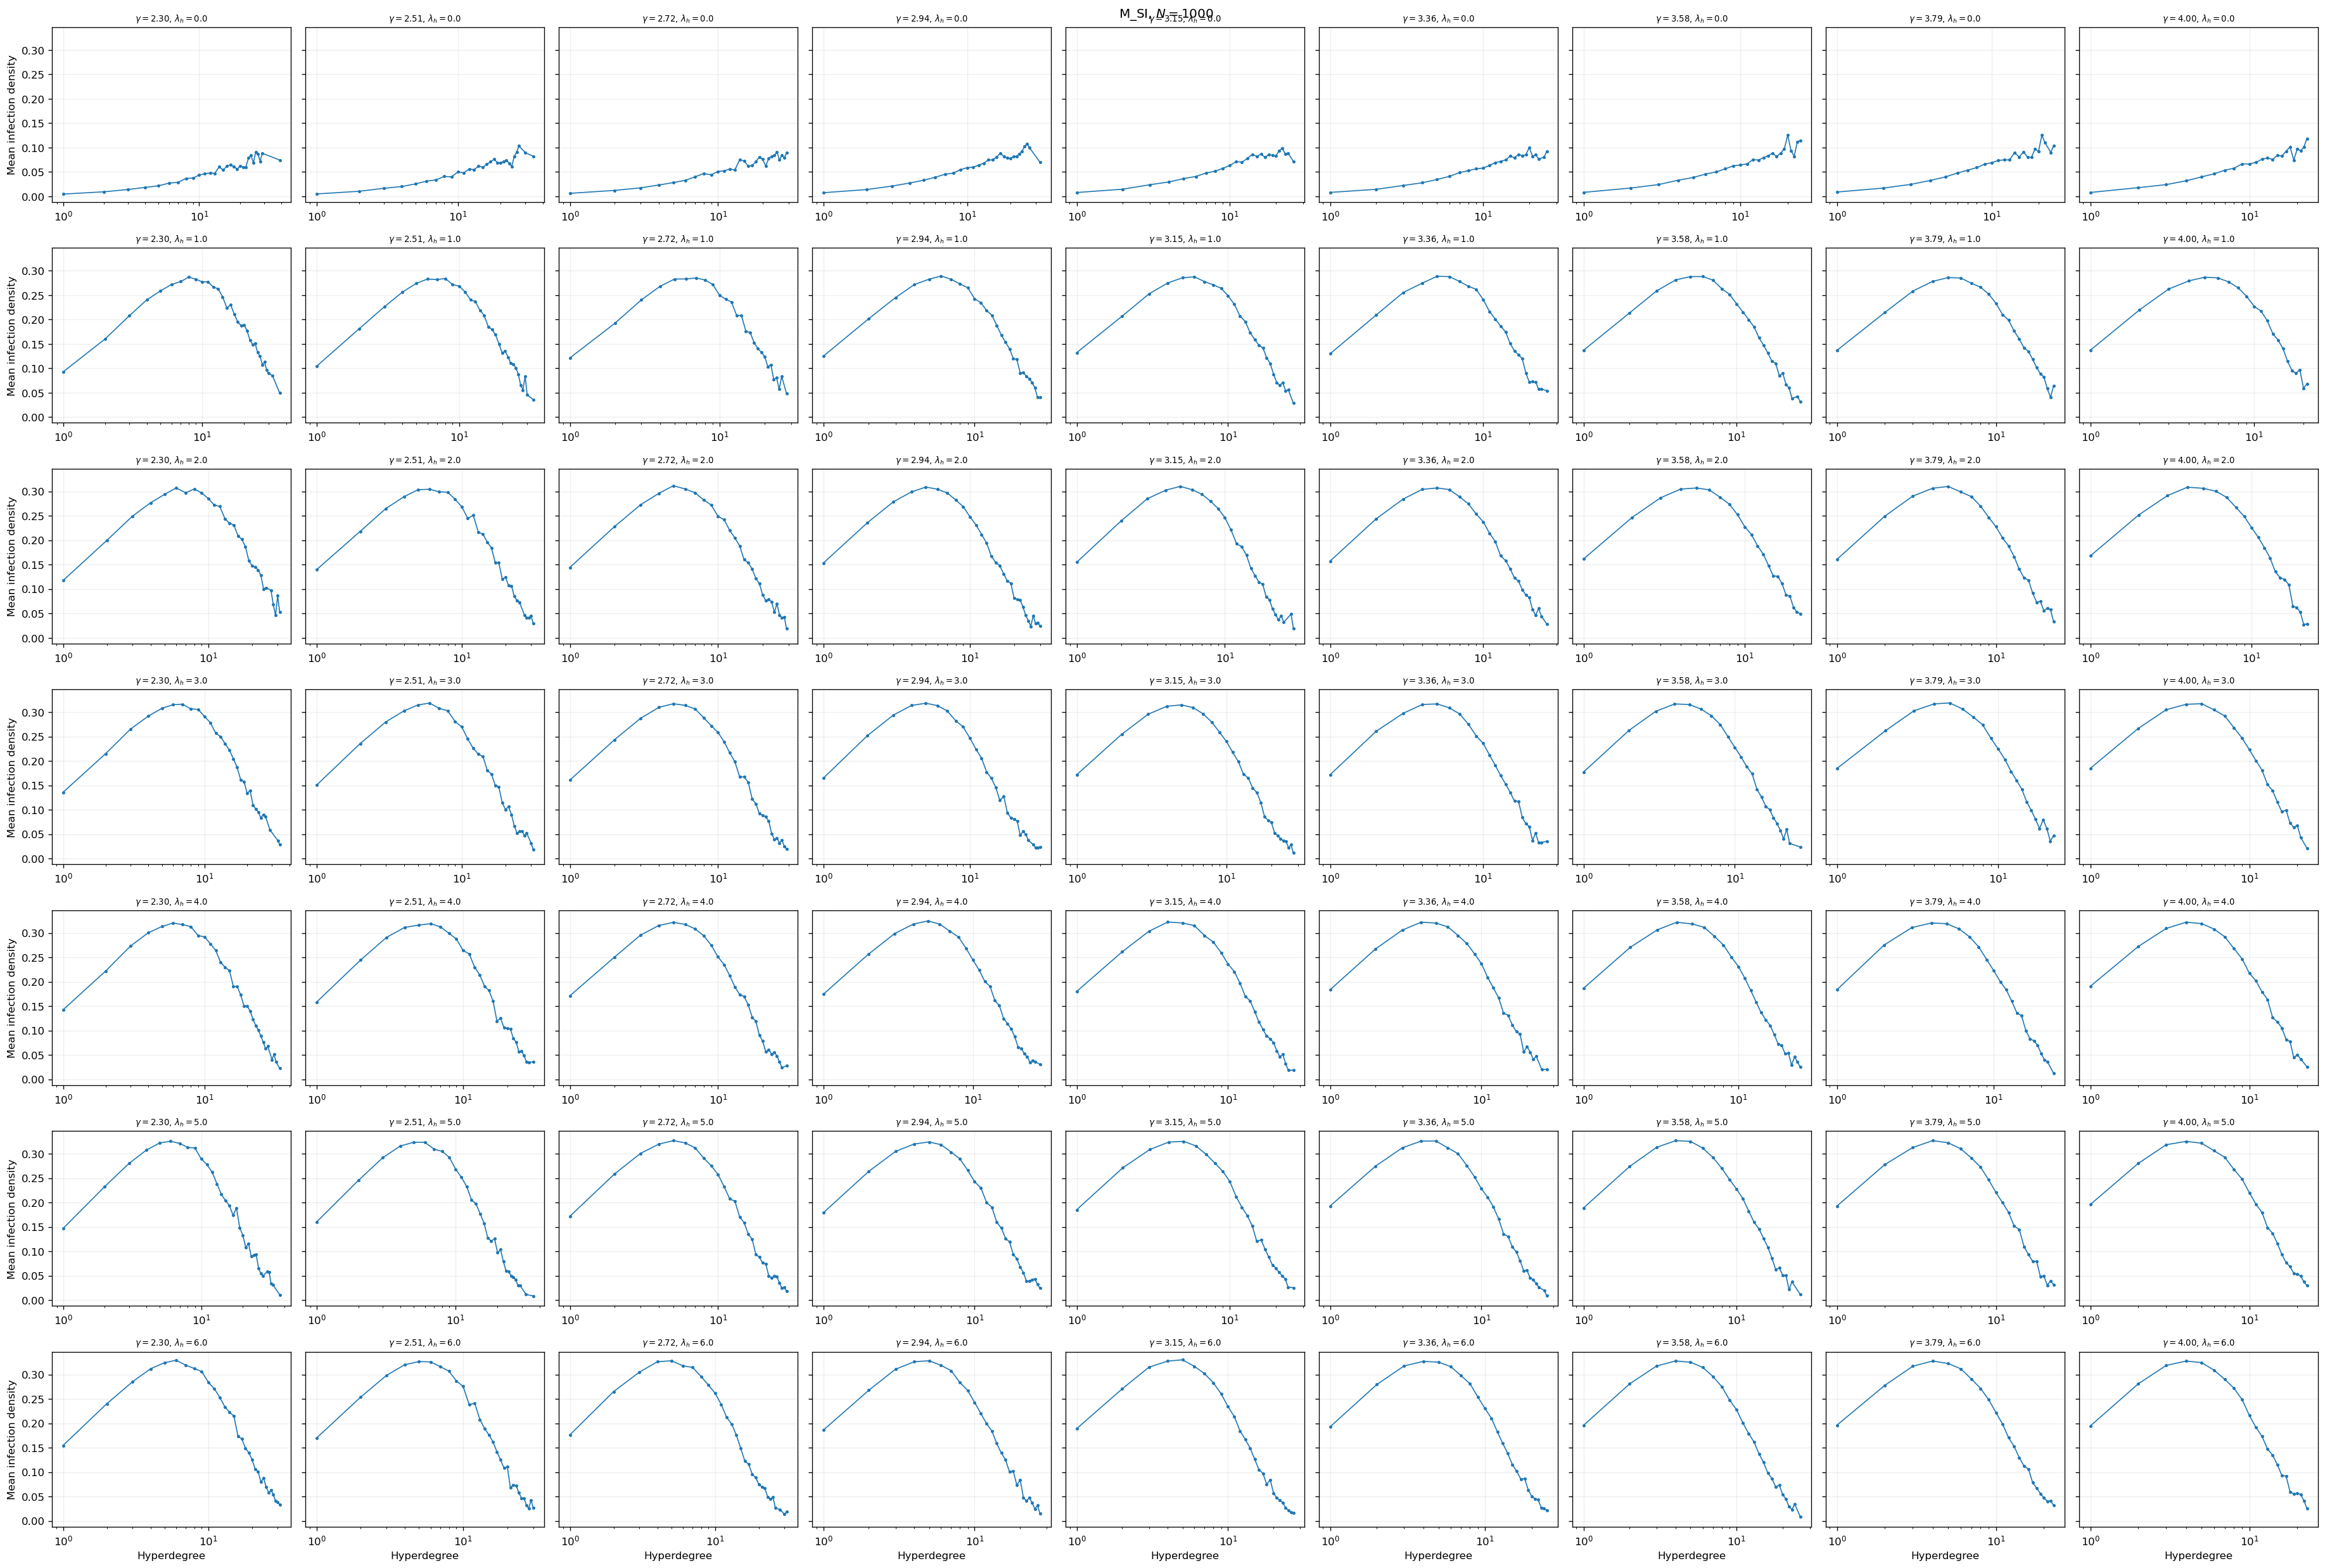

(    model  gamma  size_lambda  mean_density  sem_density
 0     M_I    2.3          0.0      0.035340     0.002437
 1     M_I    2.3          1.0      0.355451     0.009487
 2     M_I    2.3          2.0      0.493553     0.006615
 3     M_I    2.3          3.0      0.563371     0.007770
 4     M_I    2.3          4.0      0.611994     0.006745
 ..    ...    ...          ...           ...          ...
 184  M_SI    4.0          2.0      0.269392     0.000633
 185  M_SI    4.0          3.0      0.275124     0.000744
 186  M_SI    4.0          4.0      0.278396     0.000538
 187  M_SI    4.0          5.0      0.280824     0.000581
 188  M_SI    4.0          6.0      0.280906     0.000573
 
 [189 rows x 5 columns],
     model  gamma  size_lambda  fractal_dimension  intercept        r2
 0     M_I    2.3          0.0           0.586247  -0.394111  0.982841
 1     M_I    2.3          1.0           0.897024  -0.322815  0.999967
 2     M_I    2.3          2.0           0.947632  -0.340430  0.

In [9]:
# TASK 2
QUICK_TEST = False
GAMMAS = np.array([2.2, 2.8, 3.4, 4.0]) if QUICK_TEST else np.linspace(2.3, 4.0, 9)
SIZE_LAMBDAS = np.array([0.0, 1.0, 3.0]) if QUICK_TEST else np.linspace(0.0, 6.0, 7)
FINAL_N = 10**3
SCALING_SIZES = [250, 500, 1000] if QUICK_TEST else [250, 500, 1000, 2000, 4000]
SAMPLES = 2 if QUICK_TEST else 20
WORKERS = max(1, (os.cpu_count() or 2) - 1)
MEAN_DEGREE = 6.0
MAX_EDGE_SIZE = 30
MODELS = {"M_S": (1.0, 0.0), "M_I": (0.0, 1.0), "M_SI": (1.0, 1.0)}
CONFIG = dict(beta=1.4, mu=1.0, awareness_strength=1.0, synergy=1.0,
              dt=0.05 if QUICK_TEST else 0.02, t_max=15.0 if QUICK_TEST else 100.0,
              record_every=10, initial_fraction=0.1, quasi_stationary=True,
              burn_in_fraction=0.5)

def chung_lu_poisson(n, mean_degree, gamma, size_lambda, seed):
    rng = np.random.default_rng(seed)
    weights = power_law_weights(n, gamma, mean_degree, rng)
    number_of_edges = max(1, int(round(n * mean_degree / min(2.0 + size_lambda, MAX_EDGE_SIZE))))
    sizes = np.clip(2 + rng.poisson(size_lambda, number_of_edges), 2, MAX_EDGE_SIZE).astype(np.int32)
    probabilities = weights / weights.sum()
    edges = [rng.choice(n, size=min(int(k), n), replace=False, p=probabilities) for k in sizes]
    return Hypergraph.from_edges(n, edges)

def awareness_job(job):
    H = chung_lu_poisson(job["n"], MEAN_DEGREE, job["gamma"], job["size_lambda"], job["graph_seed"])
    alpha_s, alpha_i = MODELS[job["model"]]
    result = simulate_tau_leap(H, SISConfig(alpha_s=alpha_s, alpha_i=alpha_i, **CONFIG), job["process_seed"])
    summary = {"model": job["model"], "gamma": job["gamma"], "size_lambda": job["size_lambda"],
               "n": job["n"], "sample": job["sample"], "stationary_I": result["stationary_I"],
               "stationary_density": result["stationary_density"], "mean_edge_size": H.edge_sizes.mean(),
               "variance_edge_size": H.edge_sizes.var()}
    nodes = pd.DataFrame({"model": job["model"], "gamma": job["gamma"],
                          "size_lambda": job["size_lambda"], "n": job["n"],
                          "degree": result["degree"], "prevalence": result["node_prevalence"]})
    return summary, nodes

job_count = len(MODELS) * len(GAMMAS) * len(SIZE_LAMBDAS) * len(SCALING_SIZES) * SAMPLES
children = np.random.SeedSequence(20261011).spawn(job_count)
jobs, q = [], 0
for model in MODELS:
    for gamma in GAMMAS:
        for size_lambda in SIZE_LAMBDAS:
            for n in SCALING_SIZES:
                for sample in range(SAMPLES):
                    seeds = children[q].generate_state(2)
                    jobs.append({"model": model, "gamma": float(gamma), "size_lambda": float(size_lambda),
                                 "n": n, "sample": sample, "graph_seed": int(seeds[0]),
                                 "process_seed": int(seeds[1])})
                    q += 1

summaries, node_frames = [], []
with ProcessPoolExecutor(max_workers=WORKERS) as pool:
    futures = [pool.submit(awareness_job, job) for job in jobs]
    for future in as_completed(futures):
        summary, nodes = future.result()
        summaries.append(summary)
        if summary["n"] == FINAL_N:
            node_frames.append(nodes)
summary = pd.DataFrame(summaries)
nodes = pd.concat(node_frames, ignore_index=True)
summary.to_csv(SAVE_DIR+"sis_size_heterogeneity_summary.csv", index=False)
nodes.to_csv(SAVE_DIR+"sis_size_heterogeneity_nodes.csv", index=False)

final = summary[summary["n"] == FINAL_N].groupby(["model", "gamma", "size_lambda"], as_index=False).agg(
    mean_density=("stationary_density", "mean"), sem_density=("stationary_density", "sem"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
vmin, vmax = final["mean_density"].min(), final["mean_density"].max()
for ax, model in zip(axes, MODELS):
    p = final[final["model"] == model].pivot(index="size_lambda", columns="gamma", values="mean_density").sort_index().sort_index(axis=1)
    im = ax.imshow(p.values, origin="lower", aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(p.columns)), [f"{x:.2f}" for x in p.columns], rotation=45)
    ax.set_yticks(range(len(p.index)), [f"{x:.1f}" for x in p.index])
    ax.set_xlabel(r"$\gamma$"); ax.set_ylabel(r"$\lambda_h$"); ax.set_title(model)
fig.colorbar(im, ax=axes, label="Metastable infection density")
fig.savefig("sis_density_heatmaps.pdf", bbox_inches="tight")
plt.show()

averaged = summary.groupby(["model", "gamma", "size_lambda", "n"], as_index=False)["stationary_I"].mean()
fractal_rows = []
for (model, gamma, size_lambda), d in averaged.groupby(["model", "gamma", "size_lambda"]):
    d = d[(d["stationary_I"] > 0) & (d["n"] > 0)].sort_values("n")
    slope, intercept = np.polyfit(np.log(d["n"]), np.log(d["stationary_I"]), 1)
    prediction = intercept + slope * np.log(d["n"])
    observed = np.log(d["stationary_I"])
    r2 = 1 - np.sum((observed - prediction) ** 2) / max(np.sum((observed - observed.mean()) ** 2), 1e-15)
    fractal_rows.append({"model": model, "gamma": gamma, "size_lambda": size_lambda,
                         "fractal_dimension": slope, "intercept": intercept, "r2": r2})
fractal = pd.DataFrame(fractal_rows)
fractal.to_csv(SAVE_DIR+"sis_fractal_dimensions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
vmin, vmax = fractal["fractal_dimension"].min(), fractal["fractal_dimension"].max()
for ax, model in zip(axes, MODELS):
    p = fractal[fractal["model"] == model].pivot(index="size_lambda", columns="gamma", values="fractal_dimension").sort_index().sort_index(axis=1)
    im = ax.imshow(p.values, origin="lower", aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(p.columns)), [f"{x:.2f}" for x in p.columns], rotation=45)
    ax.set_yticks(range(len(p.index)), [f"{x:.1f}" for x in p.index])
    ax.set_xlabel(r"$\gamma$"); ax.set_ylabel(r"$\lambda_h$"); ax.set_title(model)
fig.colorbar(im, ax=axes, label=r"Fractal dimension $d_f$")
fig.savefig("sis_fractal_heatmaps.pdf", bbox_inches="tight")
plt.show()

degree_stats = nodes.groupby(["model", "gamma", "size_lambda", "degree"], as_index=False).agg(
    mean_prevalence=("prevalence", "mean"), observations=("prevalence", "size"))
degree_stats.to_csv(SAVE_DIR+"sis_degree_prevalence.csv", index=False)
for model in MODELS:
    fig, axes = plt.subplots(len(SIZE_LAMBDAS), len(GAMMAS), figsize=(3.4 * len(GAMMAS), 3 * len(SIZE_LAMBDAS)), squeeze=False, sharey=True)
    for row, size_lambda in enumerate(SIZE_LAMBDAS):
        for col, gamma in enumerate(GAMMAS):
            ax = axes[row, col]
            d = degree_stats[(degree_stats["model"] == model) & np.isclose(degree_stats["gamma"], gamma)
                             & np.isclose(degree_stats["size_lambda"], size_lambda)
                             & (degree_stats["degree"] > 0) & (degree_stats["observations"] >= max(5, SAMPLES))]
            ax.plot(d["degree"], d["mean_prevalence"], marker="o", markersize=2, linewidth=1)
            ax.set_xscale("log"); ax.grid(alpha=0.2)
            ax.set_title(rf"$\gamma={gamma:.2f}$, $\lambda_h={size_lambda:.1f}$", fontsize=8)
            if row == len(SIZE_LAMBDAS)-1: ax.set_xlabel("Hyperdegree")
            if col == 0: ax.set_ylabel("Mean infection density")
    fig.suptitle(rf"{model}, $N={FINAL_N}$")
    fig.tight_layout()
    fig.savefig(f"sis_degree_prevalence_{model}.pdf", bbox_inches="tight")
    plt.show()

final, fractal